<a href="https://colab.research.google.com/github/Singleeee/T2-IA-Classificacao/blob/main/Classification_limpo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tanguypledel/science-fiction-books-subgenres")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'science-fiction-books-subgenres' dataset.
Path to dataset files: /kaggle/input/science-fiction-books-subgenres


In [15]:
import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier

%matplotlib inline
sns.set_theme(style="whitegrid")

In [13]:
# 1. Leitura de todos os CSVs de subgêneros
caminho_pasta = '/kaggle/input/science-fiction-books-subgenres'
arquivos_csv = glob.glob(os.path.join(caminho_pasta, "sf_*.csv"))

lista_dfs = []
for arquivo in arquivos_csv:
    df_temp = pd.read_csv(arquivo)
    subgenero = os.path.basename(arquivo).replace('sf_', '').replace('.csv', '')
    df_temp['subgenre'] = subgenero
    lista_dfs.append(df_temp)

df = pd.concat(lista_dfs, ignore_index=True)
df = df.dropna(subset=['subgenre', 'Book_Description']).reset_index(drop=True)

# 2. Estatísticas do texto para a Seção 2 do Relatório
df['tamanho_texto'] = df['Book_Description'].apply(lambda x: len(str(x).split()))

print("=== Estatísticas Textuais do Dataset ===")
print(f"Total de Registros: {len(df)}")
print(f"Média de Palavras por Texto: {df['tamanho_texto'].mean():.2f}")
print(f"Desvio Padrão: {df['tamanho_texto'].std():.2f}")
print(f"Mínimo: {df['tamanho_texto'].min()} | Máximo: {df['tamanho_texto'].max()}\n")

# 3. Vetorização TF-IDF e Label Encoding
X_text = df['Book_Description'].astype(str)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df['subgenre'])

tfidf = TfidfVectorizer(max_features=2000, stop_words='english', ngram_range=(1, 2))
X_vectorized = tfidf.fit_transform(X_text).toarray()

# 4. Divisão 60% Treino / 20% Validação / 20% Teste
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_vectorized, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

# Separação dos 80% em 60% treino e 20% validação (20% de 100% = 25% de 80%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print("=== Divisão do Dataset (Split 60 / 20 / 20) ===")
print(f"Treino (60%):    {X_train.shape[0]} amostras")
print(f"Validação (20%): {X_val.shape[0]} amostras")
print(f"Teste (20%):     {X_test.shape[0]} amostras")

=== Estatísticas Textuais do Dataset ===
Total de Registros: 14903
Média de Palavras por Texto: 146.78
Desvio Padrão: 75.50
Mínimo: 1 | Máximo: 1514

=== Divisão do Dataset (Split 60 / 20 / 20) ===
Treino (60%):    8941 amostras
Validação (20%): 2981 amostras
Teste (20%):     2981 amostras


In [16]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None


class DecisionTreeFromScratch:
    def __init__(self, criterion='gini', max_depth=10, min_samples_split=2):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def _impurity(self, y):
        hist = np.bincount(y)
        ps = hist / len(y)
        if self.criterion == 'gini':
            return 1.0 - np.sum(ps ** 2)
        elif self.criterion == 'entropy':
            return -np.sum([p * np.log2(p) for p in ps if p > 0])
        return 0.0

    def fit(self, X, y):
        self.n_classes = len(np.unique(y))
        self.n_features = X.shape[1]
        self.root = self._build_tree(X, y)

    def _build_tree(self, X, y, depth=0):
        n_samples, n_feats = X.shape
        n_labels = len(np.unique(y))

        if depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split:
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        feat_idxs = np.random.choice(n_feats, size=min(n_feats, 100), replace=False)

        best_feat, best_thresh = self._best_split(X, y, feat_idxs)
        if best_feat is None:
            return Node(value=self._most_common_label(y))

        left_idxs, right_idxs = self._split(X[:, best_feat], best_thresh)
        left = self._build_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right = self._build_tree(X[right_idxs, :], y[right_idxs], depth + 1)
        return Node(best_feat, best_thresh, left, right)

    def _best_split(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_thresh = None, None
        parent_impurity = self._impurity(y)

        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            if len(thresholds) > 10:
                thresholds = np.percentile(X_column, np.linspace(0, 100, 10))

            for threshold in thresholds:
                left_idxs, right_idxs = self._split(X_column, threshold)
                if len(left_idxs) == 0 or len(right_idxs) == 0:
                    continue

                n = len(y)
                n_l, n_r = len(left_idxs), len(right_idxs)
                imp_l, imp_r = self._impurity(y[left_idxs]), self._impurity(y[right_idxs])
                child_impurity = (n_l / n) * imp_l + (n_r / n) * imp_r

                gain = parent_impurity - child_impurity
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = threshold

        return split_idx, split_thresh

    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    def _most_common_label(self, y):
        if len(y) == 0:
            return 0
        return np.bincount(y).argmax()

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        if node.is_leaf_node():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

In [17]:
class LogisticRegressionGD:
    def __init__(self, penalty=None, C=1.0, l1_ratio=0.5, lr=0.1, epochs=150):
        self.penalty = penalty
        self.C = C
        self.l1_ratio = l1_ratio
        self.lr = lr
        self.epochs = epochs
        self.W = None
        self.b = None
        self.history_train_loss = []
        self.history_val_loss = []

    def _softmax(self, Z):
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def _one_hot(self, y, n_classes):
        one_hot = np.zeros((len(y), n_classes))
        one_hot[np.arange(len(y)), y] = 1
        return one_hot

    def _compute_loss(self, X, y_one_hot, W):
        m = X.shape[0]
        probs = self._softmax(np.dot(X, W) + self.b)
        loss = -np.sum(y_one_hot * np.log(probs + 1e-15)) / m

        if self.penalty == 'l2':
            loss += (0.5 / self.C) * np.sum(W ** 2)
        elif self.penalty == 'l1':
            loss += (1.0 / self.C) * np.sum(np.abs(W))
        elif self.penalty == 'elasticnet':
            loss += (self.l1_ratio / self.C) * np.sum(np.abs(W)) + ((1 - self.l1_ratio) / (2 * self.C)) * np.sum(W ** 2)
        return loss

    def fit(self, X, y, X_val=None, y_val=None):
        m, n = X.shape
        n_classes = len(np.unique(y))
        y_one_hot = self._one_hot(y, n_classes)
        if y_val is not None:
            y_val_one_hot = self._one_hot(y_val, n_classes)

        self.W = np.zeros((n, n_classes))
        self.b = np.zeros((1, n_classes))

        self.history_train_loss = []
        self.history_val_loss = []

        for epoch in range(self.epochs):
            probs = self._softmax(np.dot(X, self.W) + self.b)
            dW = np.dot(X.T, (probs - y_one_hot)) / m
            db = np.sum(probs - y_one_hot, axis=0, keepdims=True) / m

            # Adicionando derivadas de Regularização
            if self.penalty == 'l2':
                dW += (1.0 / self.C) * self.W
            elif self.penalty == 'l1':
                dW += (1.0 / self.C) * np.sign(self.W)
            elif self.penalty == 'elasticnet':
                dW += (self.l1_ratio / self.C) * np.sign(self.W) + ((1 - self.l1_ratio) / self.C) * self.W

            self.W -= self.lr * dW
            self.b -= self.lr * db

            train_loss = self._compute_loss(X, y_one_hot, self.W)
            self.history_train_loss.append(train_loss)

            if X_val is not None and y_val is not None:
                val_loss = self._compute_loss(X_val, y_val_one_hot, self.W)
                self.history_val_loss.append(val_loss)

    def predict(self, X):
        probs = self._softmax(np.dot(X, self.W) + self.b)
        return np.argmax(probs, axis=1)

In [19]:
from sklearn.metrics import f1_score, precision_score, recall_score

fracs = [0.3, 0.6, 0.9]
resultados_consistencia = []

for f in fracs:
    idx = int(len(X_train) * f)
    X_sub, y_sub = X_train[:idx], y_train[:idx]

    # Treinar Árvore de Decisão
    dt = DecisionTreeFromScratch(max_depth=8)
    dt.fit(X_sub, y_sub)
    pred_tr_dt = dt.predict(X_sub)
    pred_val_dt = dt.predict(X_val)

    # Treinar Regressão Logística GD (Sem regularização)
    lr = LogisticRegressionGD(penalty=None, epochs=100)
    lr.fit(X_sub, y_sub)
    pred_tr_lr = lr.predict(X_sub)
    pred_val_lr = lr.predict(X_val)

    resultados_consistencia.append({
        'Fração Treino': f"{int(f*100)}%",
        'AD Acc Treino': accuracy_score(y_sub, pred_tr_dt),
        'AD Acc Val': accuracy_score(y_val, pred_val_dt),
        'AD F1-Macro Val': f1_score(y_val, pred_val_dt, average='macro'),
        'LR-GD Acc Treino': accuracy_score(y_sub, pred_tr_lr),
        'LR-GD Acc Val': accuracy_score(y_val, pred_val_lr),
        'LR-GD F1-Macro Val': f1_score(y_val, pred_val_lr, average='macro')
    })

df_consistencia = pd.DataFrame(resultados_consistencia)
print("=== Tabela de Análise de Consistência ===")
display(df_consistencia)

=== Tabela de Análise de Consistência ===


,Fração Treino,AD Acc Treino,AD Acc Val,AD F1-Macro Val,LR-GD Acc Treino,LR-GD Acc Val,LR-GD F1-Macro Val
0,30%,0.193512,0.152298,0.122675,0.187174,0.147937,0.106572
1,60%,0.227256,0.204294,0.180959,0.156786,0.135525,0.081027
2,90%,0.180338,0.173432,0.144379,0.338802,0.307279,0.295267


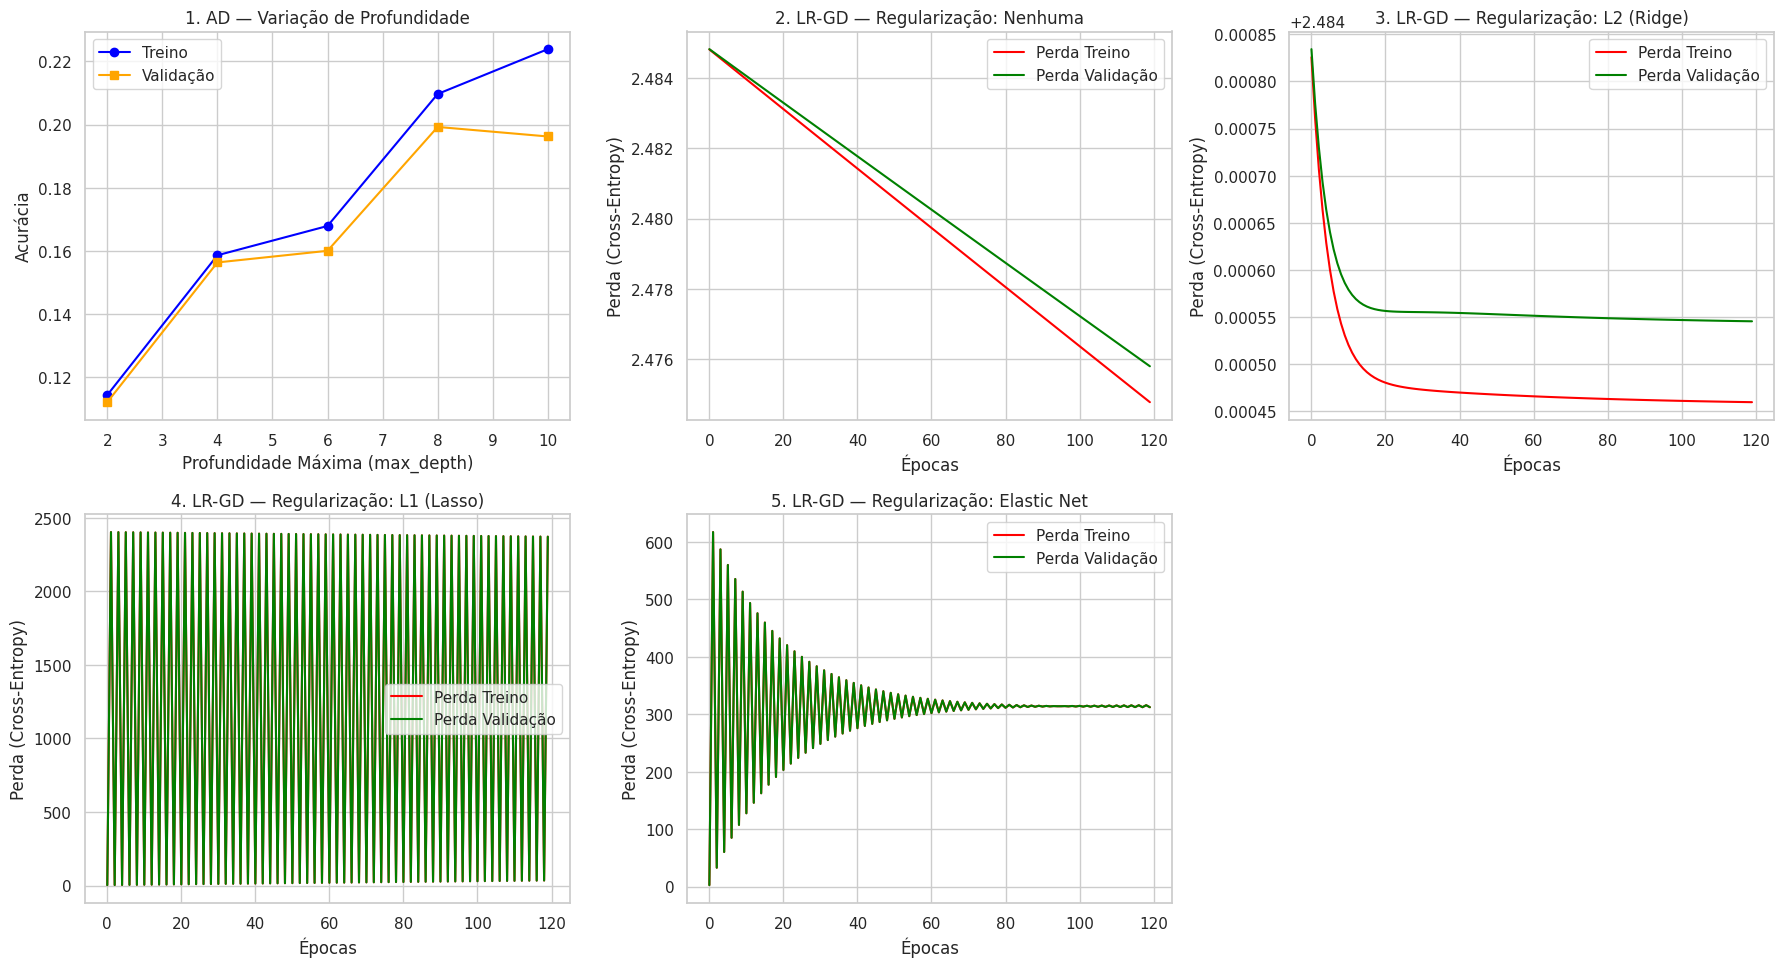

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# 1. Árvore de Decisão - Variando Max Depth
depths = range(2, 12, 2)
ad_acc_train, ad_acc_val = [], []
for d in depths:
    tree = DecisionTreeFromScratch(max_depth=d)
    tree.fit(X_train, y_train)
    ad_acc_train.append(accuracy_score(y_train, tree.predict(X_train)))
    ad_acc_val.append(accuracy_score(y_val, tree.predict(X_val)))

axes[0].plot(depths, ad_acc_train, 'o-', label='Treino', color='blue')
axes[0].plot(depths, ad_acc_val, 's-', label='Validação', color='orange')
axes[0].set_title('1. AD — Variação de Profundidade')
axes[0].set_xlabel('Profundidade Máxima (max_depth)')
axes[0].set_ylabel('Acurácia')
axes[0].legend()

# Modelos LR-GD para os gráficos de época
variantes = [
    ('Nenhuma', None, 1),
    ('L2 (Ridge)', 'l2', 2),
    ('L1 (Lasso)', 'l1', 3),
    ('Elastic Net', 'elasticnet', 4)
]

modelos_lr = {}

for nome, penalty, idx in variantes:
    model_lr = LogisticRegressionGD(penalty=penalty, C=1.0, epochs=120)
    model_lr.fit(X_train, y_train, X_val, y_val)
    modelos_lr[nome] = model_lr

    ax = axes[idx]
    ax.plot(model_lr.history_train_loss, label='Perda Treino', color='red')
    ax.plot(model_lr.history_val_loss, label='Perda Validação', color='green')
    ax.set_title(f'{idx+1}. LR-GD — Regularização: {nome}')
    ax.set_xlabel('Épocas')
    ax.set_ylabel('Perda (Cross-Entropy)')
    ax.legend()

# Remover o último subplot (vazio)
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

=== Tabela 3: Consolidação Final no Conjunto de Teste ===


,Modelo,Acurácia,Precision (Macro),Recall (Macro),Micro F1,Macro F1
0,Árvore de Decisão (do zero),0.198591,0.276352,0.198124,0.198591,0.163571
1,LR-GD Sem Regularização,0.401208,0.452571,0.399743,0.401208,0.353653
2,LR-GD Ridge (L2),0.270715,0.448838,0.269506,0.270715,0.168129
3,LR-GD Lasso (L1),0.010064,0.006552,0.010095,0.010064,0.006941
4,LR-GD Elastic Net,0.008386,0.006027,0.008416,0.008386,0.006153


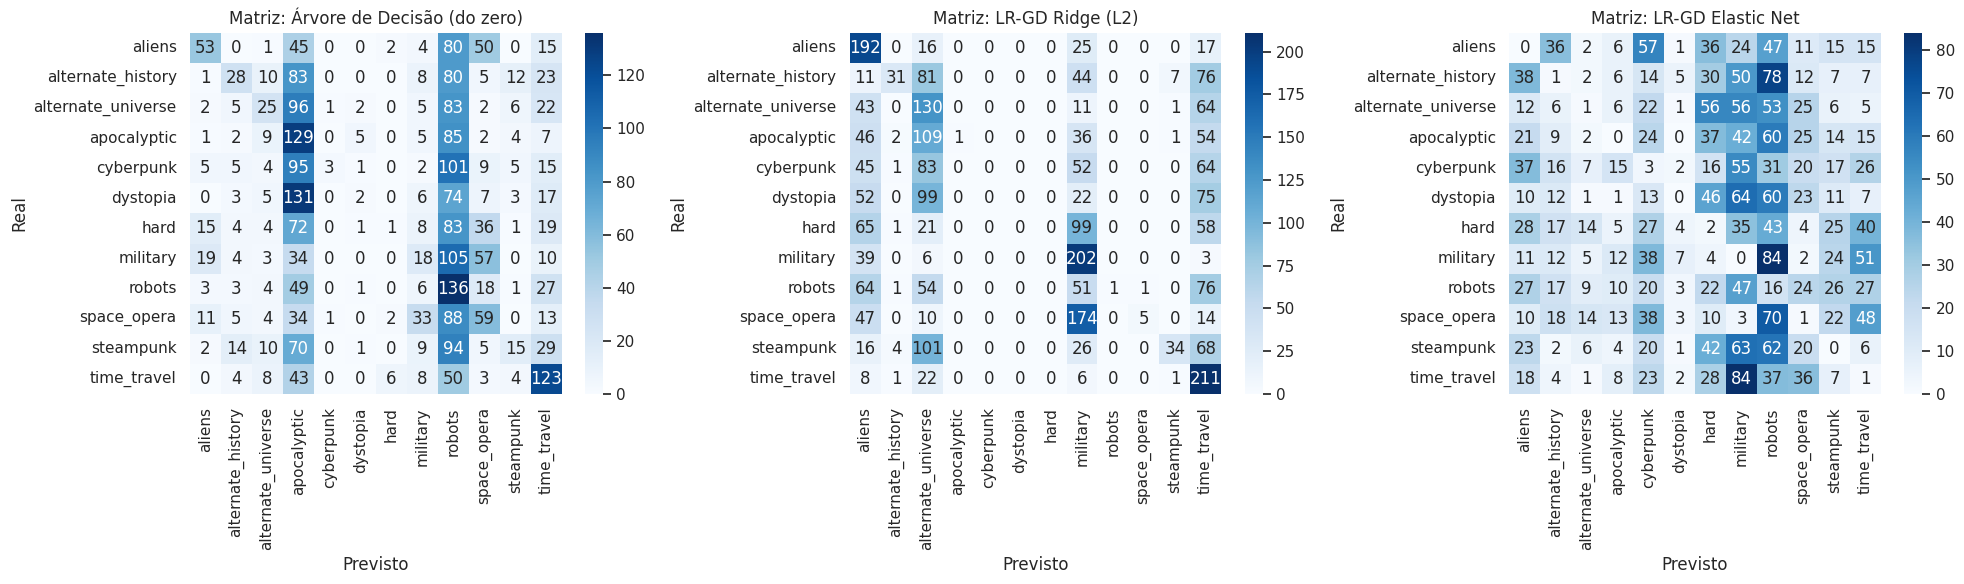

In [21]:
# Treinar os modelos finais e realizar predição no Teste
modelos_finais = {
    'Árvore de Decisão (do zero)': DecisionTreeFromScratch(max_depth=8),
    'LR-GD Sem Regularização': LogisticRegressionGD(penalty=None, epochs=120),
    'LR-GD Ridge (L2)': modelos_lr['L2 (Ridge)'],
    'LR-GD Lasso (L1)': modelos_lr['L1 (Lasso)'],
    'LR-GD Elastic Net': modelos_lr['Elastic Net']
}

# Treinar a Árvore de Decisão final e LR sem reg
modelos_finais['Árvore de Decisão (do zero)'].fit(X_train, y_train)
modelos_finais['LR-GD Sem Regularização'].fit(X_train, y_train)

métrica_resultados = []
preds_dict = {}

for nome, mod in modelos_finais.items():
    preds = mod.predict(X_test)
    preds_dict[nome] = preds

    métrica_resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, preds),
        'Precision (Macro)': precision_score(y_test, preds, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(y_test, preds, average='macro', zero_division=0),
        'Micro F1': f1_score(y_test, preds, average='micro'),
        'Macro F1': f1_score(y_test, preds, average='macro')
    })

df_metricas = pd.DataFrame(métrica_resultados)
print("=== Tabela 3: Consolidação Final no Conjunto de Teste ===")
display(df_metricas)

# Plota as Matrizes de Confusão para os 3 modelos mais significativos
top_3_modelos = ['Árvore de Decisão (do zero)', 'LR-GD Ridge (L2)', 'LR-GD Elastic Net']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, m_nome in zip(axes, top_3_modelos):
    cm = confusion_matrix(y_test, preds_dict[m_nome])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=label_encoder.classes_,
                yticklabels=label_encoder.classes_)
    ax.set_title(f'Matriz: {m_nome}', fontsize=12)
    ax.set_xlabel('Previsto')
    ax.set_ylabel('Real')

plt.tight_layout()
plt.show()